# fastai Lesson 7: Collaborative Filtering, Scaling Up and Multi-Target Models

## What is this notebook?
Lesson 7 of the fast.ai course links to three Kaggle notebooks. This one notebook combines all three, in the order that builds understanding:

| Part | Original notebook | Big idea | Runs on your PC? |
|---|---|---|---|
| **A** | *Collaborative Filtering Deep Dive* (book chapter 8) | **Recommendation systems**: guess how much a user will like a movie they have not seen, by learning hidden "taste" numbers (embeddings) | **Yes.** Small data, CPU is fine. Fully executed here. |
| **B** | *Scaling Up: Road to the Top, Part 3* | **Train bigger models on a small GPU** using *gradient accumulation*, then **ensemble** several models | **Concepts: yes** (small demos below). **The real Paddy training: Kaggle GPU.** |
| **C** | *Multi-target: Road to the Top, Part 4* | **One model, two jobs**: predict the rice *disease* and the rice *variety* at the same time | **Concepts: yes** (a toy dataset below). **The real Paddy training: Kaggle GPU.** |

## Why are we building it?
- **Part A** shows the idea behind Netflix/Spotify/Amazon-style recommendations, and builds it three ways: by hand, with fastai, and with a neural network. You will see that an *embedding* is just a table lookup, and that "deep learning for recommendations" is only a few lines on top of that.
- **Part B** answers a practical question: *"my model does not fit in GPU memory, what do I do?"* The answer (gradient accumulation) is a 5-line trick that you can prove works with plain PyTorch.
- **Part C** shows how to give one model several targets by changing only the **loss function**, which is a very general trick.

## How the notebook handles "can't run locally"
Parts B and C originally need: the 1 GB *Paddy Doctor* image dataset, the `timm` model library, and a 16 GB GPU. Rather than installing all that, this notebook:

1. **Does not install anything extra.** Everything that is Kaggle-only sits inside an `if RUN_PADDY:` block. On your PC those cells print a short "skipped" message and finish without errors.
2. **Teaches each idea with a tiny local demo** (random numbers, or a toy image dataset that we generate ourselves), so you can see the mechanics run and read the results.
3. **Works unchanged on Kaggle.** Upload the notebook, switch on the settings below, and the real Paddy cells run.

### To run the Paddy cells on Kaggle (Parts B and C)
1. Create a new Kaggle notebook and upload this file (File → Import notebook).
2. Right side → **Session options**: set **Accelerator = GPU (T4 or P100)** and **Internet = On** (needed to download pretrained weights).
3. Click **Add Input** and add the competition **Paddy Doctor: Paddy Disease Classification** (you must click "Join competition / accept rules" once on its page).
4. Run all. Leave `QUICK = True` for a first run (a few minutes); set `QUICK = False` to reproduce the full-size ensemble (very slow, see Part B).

Source notebooks: [Collaborative filtering deep dive](https://www.kaggle.com/code/jhoward/collaborative-filtering-deep-dive), [Scaling up: Road to the top, part 3](https://www.kaggle.com/code/jhoward/scaling-up-road-to-the-top-part-3), [Multi-target: Road to the top, part 4](https://www.kaggle.com/code/jhoward/multi-target-road-to-the-top-part-4).

## Words used in this notebook
| Word | Plain meaning |
|---|---|
| **Collaborative filtering** | Recommending things using only *who liked what* (no information about the movies themselves) |
| **Latent factor** | A hidden number describing a user or a movie (for example "how much sci-fi"). We never label it; the model discovers it |
| **Embedding** | A table with one row of numbers per user (or movie). "Looking up" a row is the same as multiplying by a one-hot vector |
| **Bias** | One extra number per user or movie: "this user rates everything high", "this movie is just great" |
| **Weight decay** | A penalty that keeps the model's numbers small, to stop it memorising (overfitting) |
| **Gradient accumulation** | Add up gradients from several small batches before updating, to imitate one big batch with less memory |
| **TTA (test-time augmentation)** | Predict on several slightly altered copies of each test image and average, for a steadier answer |
| **Ensemble** | Average the predictions of several models |
| **Multi-target** | One model that predicts more than one thing |

## Setup: imports and "where am I running?"

In [2]:
import os, gc, importlib.util
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from fastai.collab import *          # collaborative-filtering tools: CollabDataLoaders, collab_learner, ...
from fastai.tabular.all import *     # also gives us untar_data, URLs, Module, Embedding, delegates, ...
from fastai.vision.all import *      # image tools used in Parts B and C: DataBlock, ImageBlock, vision_learner, ...

set_seed(42)                         # makes random numbers repeatable, so results are similar on every run

# Are we on Kaggle? Kaggle sets this environment variable inside its notebooks.
iskaggle = bool(os.environ.get('KAGGLE_KERNEL_RUN_TYPE'))
print('Running on Kaggle:', iskaggle)

c:\Users\Pranav\Documents\andrew-ng-ml-course\foundations\.venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Running on Kaggle: False


**What the lines do**
- `from fastai.collab import *` etc.: fastai is designed to be imported with `*`, which brings in hundreds of helpers at once (tabular, collab and vision tools). That is why you will see names like `Embedding` or `Learner` used below without an obvious import.
- `set_seed(42)`: PyTorch uses random numbers to start the model. Fixing the seed makes your results close to (not always identical to) the ones described in the text.
- `iskaggle`: `os.environ.get('KAGGLE_KERNEL_RUN_TYPE')` is only set on Kaggle. The original notebooks use the same trick through the `fastkaggle` helper library; we do it in one line instead, so there is nothing to install.

In [3]:
# Decide whether the heavy Paddy cells (Parts B and C) can run in this session.
paddy_candidates = [Path('/kaggle/input/paddy-disease-classification'),   # Kaggle: where an attached competition appears
                    Path('paddy-disease-classification')]                  # your PC: if you downloaded + unzipped it here
PADDY_PATH = next((p for p in paddy_candidates if p.exists()), None)

has_gpu  = torch.cuda.is_available()                              # is there an NVIDIA GPU PyTorch can use?
has_timm = importlib.util.find_spec('timm') is not None           # is the 'timm' model library installed?

RUN_PADDY = bool(PADDY_PATH) and has_gpu and has_timm             # all three are required
QUICK = True                                                      # True = small/fast run, False = the original full-size run

print('Paddy data found :', PADDY_PATH)
print('GPU available    :', has_gpu)
print('timm installed   :', has_timm)
print('RUN_PADDY        :', RUN_PADDY, '  (if False, the Kaggle-only cells below are skipped)')

Paddy data found : None
GPU available    : False
timm installed   : False
RUN_PADDY        : False   (if False, the Kaggle-only cells below are skipped)


**What the lines do**
- `paddy_candidates` / `PADDY_PATH`: look for the competition data in the two places it could be (Kaggle's input folder, or a folder on your PC). `next(..., None)` returns the first folder that exists, or `None`.
- `importlib.util.find_spec('timm')`: asks Python "could I import `timm`?" without actually importing it, so a missing library does not cause an error.
- `RUN_PADDY`: `True` only if the data **and** a GPU **and** `timm` are all present. Every Kaggle-only cell starts with `if RUN_PADDY:`.
- `QUICK`: a switch for Kaggle runs. `True` trains two small models for 2 epochs (minutes). `False` trains the original four large architectures for 12 epochs each (hours).

---
# PART A: Collaborative filtering (runs locally)

## What are we building?
A model that is given a **user** and a **movie** and predicts **the star rating (0.5 to 5)** that user would give. Once it can do that, recommending is easy: show each user the movies with the highest predicted rating that they have not seen.

## The key idea
Suppose each movie is described by a few hidden numbers (for example *how sci-fi it is*, *how recent it is*, *how much action*), and each user by the same kind of numbers (*how much they like sci-fi*, ...). Then a good guess for the rating is **how well the two lists of numbers line up**, which is the **dot product** (multiply matching numbers, add them up).

The catch: nobody gave us those numbers. So we start with **random** numbers and let gradient descent (the same method as in the PyTorch-from-scratch notebook) adjust them until the predicted ratings match the real ratings. The numbers that come out are the *latent factors*.

## The data: MovieLens 100k
100,000 ratings, from 943 users on 1,682 movies. Each row says "this user gave this movie this rating at this time".

In [4]:
path = untar_data(URLs.ML_100k)      # downloads (once, ~5 MB) and unzips the MovieLens-100k dataset; returns the folder
ratings = pd.read_csv(path/'u.data', delimiter='\t', header=None,
                      names=['user','movie','rating','timestamp'])
ratings.head()

,user,movie,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


**What the lines do**
- `untar_data(URLs.ML_100k)`: fastai downloads the file into `~/.fastai/data` the first time, and just reuses it afterwards.
- `pd.read_csv(..., delimiter='\t', header=None, names=[...])`: the file `u.data` is *tab*-separated and has no header row, so we say that and name the four columns ourselves.
- Each row is one rating: user number, movie number, stars, and a timestamp (we ignore the timestamp).

Notice what is **missing**: the movies' names, genres, years. We only know who rated what. Collaborative filtering works from that alone.

In [5]:
print(ratings.shape, ' ratings')
print(ratings.user.nunique(), 'users,', ratings.movie.nunique(), 'movies')
# Fraction of the full user x movie grid that is actually filled in
print('filled-in fraction of the grid: %.1f%%' % (100*len(ratings)/(ratings.user.nunique()*ratings.movie.nunique())))

(100000, 4)  ratings
943 users, 1682 movies
filled-in fraction of the grid: 6.3%


Only a small percentage of the "every user x every movie" grid is filled in. Imagine that grid as a giant spreadsheet with mostly empty cells. **Collaborative filtering = filling in the blank cells.**

### A hand-made example of latent factors
Let us invent three hidden factors per movie: `[science-fiction, action, old-movie]`. Here is *Last Skywalker* (very sci-fi, very action, not old) and a user who likes sci-fi and action and dislikes old movies:

In [6]:
last_skywalker = np.array([0.98, 0.9, -0.9])    # movie: very sci-fi, quite action, NOT old (negative = "not old")
user1          = np.array([0.9, 0.8, -0.6])     # user: loves sci-fi, likes action, prefers newer movies
(user1 * last_skywalker).sum()                  # dot product: multiply matching numbers and add them up

np.float64(2.1420000000000003)

In [7]:
casablanca = np.array([-0.99, -0.3, 0.8])       # movie: not sci-fi, not action, an old classic
(user1 * casablanca).sum()                      # the same user, a very different movie

np.float64(-1.611)

**What the lines do**
- `user1 * last_skywalker`: multiplies the arrays *element by element* (`0.9*0.98`, `0.8*0.9`, `-0.6*-0.9`).
- `.sum()` adds those three products. Together, `(a*b).sum()` is the **dot product**.
- Big positive result (about 2.1) = "this user will probably love this movie". Negative result (about -1.6) = "probably not". Same user, different movie, opposite outcomes, which is exactly the signal we want.

The real model does the same thing, but the numbers are **learned**, and there are 50 of them per user and per movie instead of 3.

### Learning the latent factors
Steps we will follow:
1. Give every user and every movie a random list of numbers.
2. Predict each rating as the dot product of the user's and the movie's numbers.
3. Measure how wrong the predictions are (loss = mean squared error).
4. Use gradient descent to nudge all the numbers to reduce the loss. Repeat.

### Creating the DataLoaders
Movie numbers like `1` or `1357` are hard to read, so first we load the movie titles and attach them.

In [8]:
movies = pd.read_csv(path/'u.item', delimiter='|', encoding='latin-1',
                     usecols=(0,1), names=('movie','title'), header=None)
movies.head()

,movie,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [9]:
ratings = ratings.merge(movies)      # join the two tables on the shared column 'movie', adding a 'title' column
ratings.head()

,user,movie,rating,timestamp,title
0,196,242,3,881250949,Kolya (1996)
1,186,302,3,891717742,L.A. Confidential (1997)
2,22,377,1,878887116,Heavyweights (1994)
3,244,51,2,880606923,Legends of the Fall (1994)
4,166,346,1,886397596,Jackie Brown (1997)


**What the lines do**
- `usecols=(0,1)`: the file has many columns (genre flags etc.); we only keep the first two (movie number, title).
- `encoding='latin-1'`: the titles contain accented characters that the default decoder cannot read.
- `ratings.merge(movies)`: like a spreadsheet lookup: for each rating, find the matching movie number in `movies` and add its title.

> **Re-run note:** `ratings.merge(movies)` is safe to run twice (it replaces `ratings` with the merged table; the second merge just finds `title` already present and joins again on `movie` and `title`).

In [10]:
dls = CollabDataLoaders.from_df(ratings, item_name='title', bs=64, num_workers=0)   # bs=64: 64 ratings per step; num_workers=0: load data in the main process (most reliable on Windows)
dls.show_batch()                                                      # peek at one batch of (user, title, rating)

c:\Users\Pranav\Documents\andrew-ng-ml-course\foundations\.venv\Lib\site-packages\fastai\torch_core.py:155: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  else as_tensor(x.values, **kwargs) if isinstance(x, (pd.Series, pd.DataFrame))


,user,title,rating
0,782,Starship Troopers (1997),2
1,943,Judge Dredd (1995),3
2,758,Mission: Impossible (1996),4
3,94,Farewell My Concubine (1993),5
4,23,Psycho (1960),4
5,296,Secrets & Lies (1996),5
6,940,"American President, The (1995)",4
7,334,Star Trek VI: The Undiscovered Country (1991),1
8,380,Braveheart (1995),4
9,690,So I Married an Axe Murderer (1993),1


**What the lines do**
- `CollabDataLoaders.from_df(...)`: turns the table into training and validation batches. By default it takes the first column as the user, `item_name='title'` says "the thing being rated is in the `title` column", and the rating column is the target. It also converts every user and title into a small integer index, and holds a 80/20 train/validation split.
- `bs=64`: 64 ratings per batch.
- `num_workers=0`: load batches in the main process instead of starting helper processes. The data is tiny and already in memory, so helpers give no speed-up, and on Windows they can hang inside Jupyter.
- `show_batch()` prints a few rows so you can check it understood the table correctly.

### What is an embedding? (It is just a lookup)
If we put the random numbers into a matrix with one **row per user**, then "get user 3's numbers" can be done two ways: just read row 3, or multiply the matrix by a **one-hot vector** (all zeros except a 1 in position 3). Both give the same thing. Deep learning libraries call the "just read row 3" version an **embedding**, because it is much faster than a big matrix multiplication.

In [11]:
n_users   = len(dls.classes['user'])      # how many different users the DataLoaders found
n_movies  = len(dls.classes['title'])     # how many different movies
n_factors = 5                             # hidden numbers per user/movie (small, just for this demo)

user_factors  = torch.randn(n_users,  n_factors)    # a random 'taste' row for every user
movie_factors = torch.randn(n_movies, n_factors)    # a random 'features' row for every movie
print(n_users, n_movies, user_factors.shape, movie_factors.shape)

944 1665 torch.Size([944, 5]) torch.Size([1665, 5])


In [12]:
one_hot_3 = one_hot(3, n_users).float()       # a vector of zeros with a 1 at position 3
print(one_hot_3[:8], '...')
print(user_factors.t() @ one_hot_3)           # matrix multiplication with the one-hot vector ...
print(user_factors[3])                        # ... gives exactly the same numbers as simply reading row 3

tensor([0., 0., 0., 1., 0., 0., 0., 0.]) ...
tensor([-0.4586, -0.9915, -0.4052, -0.3621, -0.5908])
tensor([-0.4586, -0.9915, -0.4052, -0.3621, -0.5908])


**What the lines do**
- `torch.randn(a, b)`: a random `a x b` table (normal distribution).
- The printout says 944 users and 1665 movies, one more than the 943 users and 1,664 distinct titles in the data (1,682 movie ids, but a few ids share a title). The extra row in each is a placeholder fastai adds (`#na#`) for "unknown" values.
- `one_hot(3, n_users)`: a vector of length `n_users`, all zeros except position 3.
- `.t()` is transpose, `@` is matrix multiplication. The product selects row 3, the same as `user_factors[3]`.
- The take-away: an **embedding is a lookup table whose entries are trained**. `Embedding(n, k)` is a table of `n` rows and `k` columns.

### Collaborative filtering from scratch: a `DotProduct` model
Here we write the model as a PyTorch module. First a 30-second refresher on Python classes, because the model is a class:

In [12]:
class Example:
    def __init__(self, a): self.a = a                  # runs when you create an object; stores 'a' on it
    def say(self, x): return f'Hello {self.a}, {x}.'   # a method that can use the stored 'a'

ex = Example('Sylvain')
ex.say('nice to meet you')

'Hello Sylvain, nice to meet you.'

A PyTorch model is a class with two special methods:
- `__init__`: create the pieces that hold the numbers to be learned (here: the two embeddings).
- `forward`: say how to turn an input batch into predictions. PyTorch calls it for you when you write `model(x)`.

fastai's `Module` is a small convenience version of PyTorch's `nn.Module` that calls the parent `__init__` for you.

In [13]:
class DotProduct(Module):
    def __init__(self, n_users, n_movies, n_factors):
        self.user_factors  = Embedding(n_users,  n_factors)    # trainable table: one row of n_factors numbers per user
        self.movie_factors = Embedding(n_movies, n_factors)    # trainable table: one row per movie

    def forward(self, x):                                      # x is a batch: column 0 = user index, column 1 = movie index
        users  = self.user_factors(x[:,0])                     # look up each user's numbers   -> (batch, n_factors)
        movies = self.movie_factors(x[:,1])                    # look up each movie's numbers  -> (batch, n_factors)
        return (users * movies).sum(dim=1)                     # dot product per row           -> (batch,) predicted ratings

In [14]:
x, y = dls.one_batch()          # grab one batch: x = inputs, y = true ratings
print('x shape:', x.shape, '(64 rows, [user, movie])')
print('y shape:', y.shape)
print(x[:3], y[:3])

x shape: torch.Size([64, 2]) (64 rows, [user, movie])
y shape: torch.Size([64, 1])
tensor([[ 867, 1330],
        [ 489,  899],
        [ 321,  230]]) tensor([[5],
        [2],
        [4]], dtype=torch.int8)


**What the lines do**
- `x[:,0]` means "every row, column 0" = the user index of every rating in the batch. `x[:,1]` is the movie index.
- `self.user_factors(x[:,0])` is the embedding lookup: for 64 users it returns a `(64, n_factors)` table.
- `(users * movies).sum(dim=1)`: multiply element-wise, then add across the factors. That gives **one predicted rating per row**.

### Training it
`Learner` ties together data, model and loss. `MSELossFlat` is mean squared error (average of `(prediction - truth)²`), which is the natural loss for "guess a number".

In [15]:
model = DotProduct(n_users, n_movies, 50)                   # 50 hidden numbers per user and per movie
learn = Learner(dls, model, loss_func=MSELossFlat())        # data + model + loss; fastai handles the training loop
learn.fit_one_cycle(5, 5e-3)                                # 5 passes over the data, max learning rate 0.005

epoch,train_loss,valid_loss,time


**What the lines do**
- `Learner(dls, model, loss_func=...)`: fastai's training wrapper (the same idea as `tabular_learner` earlier, but with *our own* model).
- `fit_one_cycle(5, 5e-3)`: trains for 5 epochs. "One cycle" means the learning rate starts small, rises to `5e-3`, then falls again. This is fastai's default recommendation and usually trains faster and better than a constant rate.
- Watch the **validation loss** (`valid_loss`), the mean squared error on ratings the model has not trained on. A mean squared error of about 0.9 means predictions are typically off by roughly 0.9 stars (the square root of the loss).

In our run both losses fell for all 5 epochs, ending with a validation loss of about 0.87. But this model has a hidden weakness: it can predict impossible ratings. The next three improvements fix that and fight **overfitting** (the model memorising the training ratings instead of learning general taste).

### Improvement 1: squash predictions into the valid rating range
Ratings are between 0.5 and 5, but our dot product can produce any number (even 20 or -7). `sigmoid_range(x, lo, hi)` squeezes any number smoothly into the range `(lo, hi)`. We use `5.5` rather than `5` as the top, because a sigmoid never quite *reaches* its limit, so using 5.5 lets the model get close to a perfect 5.

In [16]:
class DotProduct(Module):
    def __init__(self, n_users, n_movies, n_factors, y_range=(0, 5.5)):
        self.user_factors  = Embedding(n_users,  n_factors)
        self.movie_factors = Embedding(n_movies, n_factors)
        self.y_range = y_range                                   # remember the allowed range

    def forward(self, x):
        users  = self.user_factors(x[:,0])
        movies = self.movie_factors(x[:,1])
        return sigmoid_range((users * movies).sum(dim=1), *self.y_range)   # squash the result into (0, 5.5)

In [17]:
model = DotProduct(n_users, n_movies, 50)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3)

epoch,train_loss,valid_loss,time


`*self.y_range` "unpacks" the tuple `(0, 5.5)` into two separate arguments, so the call is `sigmoid_range(value, 0, 5.5)`.

### Improvement 2: add a bias for each user and each movie
The dot product cannot say "this movie is just generally loved" or "this user is generally grumpy". Those are properties of the movie/user alone, not of the *match*. So we add **one extra number per user and per movie** (the *bias*) to the prediction.

In [18]:
class DotProductBias(Module):
    def __init__(self, n_users, n_movies, n_factors, y_range=(0, 5.5)):
        self.user_factors  = Embedding(n_users,  n_factors)
        self.user_bias     = Embedding(n_users,  1)               # ONE number per user: "how generous is this user?"
        self.movie_factors = Embedding(n_movies, n_factors)
        self.movie_bias    = Embedding(n_movies, 1)               # ONE number per movie: "how good is this movie in general?"
        self.y_range = y_range

    def forward(self, x):
        users  = self.user_factors(x[:,0])
        movies = self.movie_factors(x[:,1])
        res = (users * movies).sum(dim=1, keepdim=True)           # keepdim=True keeps shape (batch,1) so we can add biases
        res += self.user_bias(x[:,0]) + self.movie_bias(x[:,1])   # add the user's and the movie's bias
        return sigmoid_range(res, *self.y_range)

In [19]:
model = DotProductBias(n_users, n_movies, 50)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3)

epoch,train_loss,valid_loss,time


`keepdim=True` makes the sum keep a shape of `(batch, 1)` instead of `(batch,)`. The biases come out of `Embedding(..., 1)` with shape `(batch, 1)`, so the shapes must match before adding.

Look closely at the table from a typical run: the **training** loss keeps falling (to about 0.3), but the **validation** loss bottoms out after about 2 epochs (around 0.91) and then **rises** (to about 0.95). The model is **overfitting**: it is memorising the training ratings. (The version without biases showed the same pattern, with a validation loss that stalled around 0.95 while training loss kept falling.) We need a different tool.

### Improvement 3: weight decay (regularisation)
**Overfitting** happens when the model's numbers grow large and "memorise" individual ratings. **Weight decay** adds a penalty `wd * sum(weights²)` to the loss, so large numbers are discouraged and the model has to find simpler, more general patterns.

Why squares? Look at the shape of `a * x²`: the larger `a`, the steeper and narrower the bowl, which punishes big weights more:

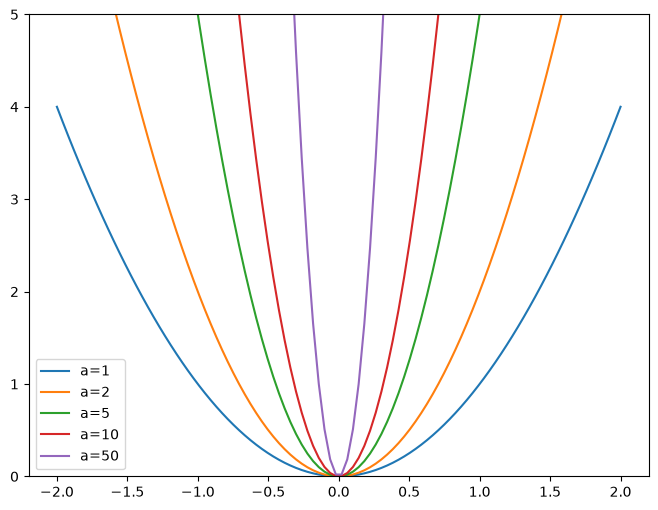

In [20]:
x = np.linspace(-2, 2, 100)                    # 100 evenly spaced x values from -2 to 2
a_s = [1, 2, 5, 10, 50]                        # five different steepness values
ys = [a * x**2 for a in a_s]
_, ax = plt.subplots(figsize=(8, 6))
for a, y in zip(a_s, ys): ax.plot(x, y, label=f'a={a}')
ax.set_ylim([0, 5])
ax.legend();

In fastai you simply pass `wd=...` to `fit_one_cycle`. It adds the penalty (actually it is applied directly to the weights during the update, which is equivalent and cheaper). `wd=0.1` is a good value here, and typical values are 0.01 to 0.1.

In [20]:
model = DotProductBias(n_users, n_movies, 50)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3, wd=0.1)           # same as before + a penalty on large weights

epoch,train_loss,valid_loss,time
0,0.907658,0.954014,00:07
1,0.672682,0.894207,00:06
2,0.537963,0.877620,00:07
3,0.454539,0.860992,00:07
4,0.433001,0.857460,00:06


Compare with the previous run: the **training loss now falls more slowly** (about 0.43 instead of 0.30 at the end, because the model is not allowed to memorise) but the **validation loss ends up lower (about 0.86 instead of 0.95) and keeps falling instead of climbing**. That is what regularisation is for: it gives up a little training fit in exchange for better predictions on unseen data.

### Creating our own Embedding module
So far we used fastai's `Embedding`. How would you build one yourself? In PyTorch, a number is only *trained* if it is wrapped in `nn.Parameter`. Here is the difference:

In [21]:
class T(Module):
    def __init__(self): self.a = torch.ones(3)             # a plain tensor: PyTorch does NOT know it is a model weight

L(T().parameters())                                        # -> empty list: nothing to train!

[]

In [22]:
class T(Module):
    def __init__(self): self.a = nn.Parameter(torch.ones(3))    # wrapped in nn.Parameter: registered as a trainable weight

L(T().parameters())                                              # -> one parameter found

[Parameter containing:
tensor([1., 1., 1.], requires_grad=True)]

In [23]:
class T(Module):
    def __init__(self): self.a = nn.Linear(1, 3, bias=False)    # PyTorch layers register their own parameters automatically

t = T()
L(t.parameters())

[Parameter containing:
tensor([[-0.3292],
        [-0.8623],
        [ 0.0592]], requires_grad=True)]

In [24]:
type(t.a.weight)               # it's an nn.Parameter inside: that is what makes it trainable

torch.nn.parameter.Parameter

**Take-away:** if you create a tensor in `__init__` and want it learned, wrap it in `nn.Parameter` (or use a built-in layer like `nn.Linear` / `Embedding`, which does it for you).

Now our own version of the "random small starting numbers" helper, and a `DotProductBias` that uses plain parameter tables and **indexes** them directly with `table[indices]`. This is exactly what an embedding does.

In [25]:
def create_params(size):
    return nn.Parameter(torch.zeros(*size).normal_(0, 0.01))   # a trainable table of tiny random numbers (mean 0, std 0.01)

In [26]:
class DotProductBias(Module):
    def __init__(self, n_users, n_movies, n_factors, y_range=(0, 5.5)):
        self.user_factors  = create_params([n_users,  n_factors])   # our own 'embedding' tables
        self.user_bias     = create_params([n_users])
        self.movie_factors = create_params([n_movies, n_factors])
        self.movie_bias    = create_params([n_movies])
        self.y_range = y_range

    def forward(self, x):
        users  = self.user_factors[x[:,0]]                          # plain indexing = the embedding lookup
        movies = self.movie_factors[x[:,1]]
        res = (users * movies).sum(dim=1)
        res += self.user_bias[x[:,0]] + self.movie_bias[x[:,1]]
        return sigmoid_range(res, *self.y_range)

In [27]:
model = DotProductBias(n_users, n_movies, 50)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3, wd=0.1)

epoch,train_loss,valid_loss,time
0,0.880205,0.939790,00:07
1,0.674960,0.889318,00:06
2,0.504024,0.871321,00:06
3,0.454239,0.858725,00:06
4,0.436549,0.854857,00:06


The results are similar to the version with fastai's `Embedding`, since it is the same computation. You now understand what an embedding layer is made of.

## Interpreting embeddings and biases
The trained numbers are not random any more, they mean something. Let us look.

### Biases: which movies are loved or hated *regardless of taste*?
`movie_bias` holds one number per movie: how much **higher or lower** than average it is rated, after the factors have explained the "matching" part.

In [28]:
movie_bias = learn.model.movie_bias                         # the learned per-movie bias values (one per movie)
idxs = movie_bias.argsort()[:5]                             # positions of the 5 LOWEST biases
[dls.classes['title'][i] for i in idxs]                     # turn those positions back into titles

['Lawnmower Man 2: Beyond Cyberspace (1996)',
 'Children of the Corn: The Gathering (1996)',
 'Showgirls (1995)',
 'Leave It to Beaver (1997)',
 'Grease 2 (1982)']

In [29]:
idxs = movie_bias.argsort(descending=True)[:5]              # the 5 HIGHEST biases
[dls.classes['title'][i] for i in idxs]

['Shawshank Redemption, The (1994)',
 'Good Will Hunting (1997)',
 'Titanic (1997)',
 "Schindler's List (1993)",
 'Rear Window (1954)']

**What the lines do**
- `argsort()` returns the *positions* that would sort the values. `[:5]` takes the first five (lowest values). `descending=True` flips it to the highest.
- `dls.classes['title']` is the list that maps a position back to a movie title.

These are movies that people dislike (or like) **even after allowing for personal taste**. In our run the lowest were *Lawnmower Man 2*, *Children of the Corn: The Gathering*, *Showgirls*, *Leave It to Beaver* and *Grease 2*, and the highest were *Shawshank Redemption*, *Good Will Hunting*, *Titanic*, *Schindler's List* and *Rear Window*. Your list may differ slightly because training starts from random numbers.

### Factors: what did the model learn about taste?
Each movie has 50 numbers, too many to look at. **PCA** (principal component analysis) squeezes 50 numbers into 3, keeping the directions along which movies differ the most. We plot the 50 most-rated movies on two of them.

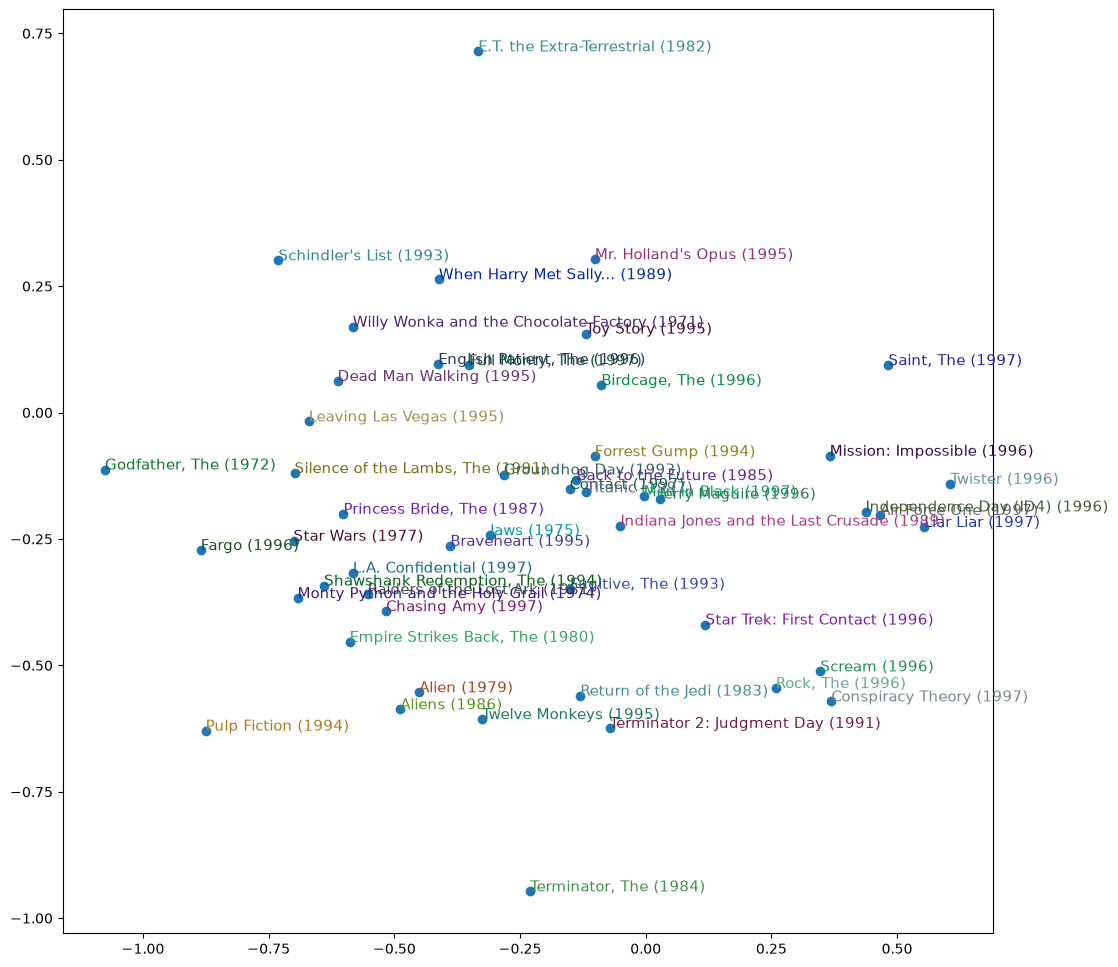

In [30]:
g = ratings.groupby('title')['rating'].count()                          # how many ratings each movie has
top_movies = g.sort_values(ascending=False).index.values[:1000]         # the 1000 most-rated movies (well-trained, trustworthy)
top_idxs = tensor([learn.dls.classes['title'].o2i[m] for m in top_movies])   # title -> position (o2i = "object to index")
movie_w = learn.model.movie_factors[top_idxs].cpu().detach()            # their learned factor rows, detached from training
movie_pca = movie_w.pca(3)                                              # 50 numbers -> 3 numbers per movie
fac0, fac1, fac2 = movie_pca.t()                                        # split into three columns
idxs = list(range(50))                                                  # plot only the 50 most popular movies
X = fac0[idxs]
Y = fac2[idxs]
plt.figure(figsize=(12, 12))
plt.scatter(X, Y)
for i, x, y in zip(top_movies[idxs], X, Y):
    plt.text(x, y, i, color=np.random.rand(3)*0.7, fontsize=11)         # label each dot with the movie title
plt.show()

**How to read the plot:** movies that are close together have similar learned factors, i.e. the same kind of people like them. Look for groups of related movies (sequels or same-genre films sitting near each other) and for which movies sit at the far ends of an axis. Nobody told the model about genres; whatever structure appears was found by itself from the ratings alone. The exact picture changes from run to run, because the starting numbers are random.

The pieces used: `.cpu().detach()` moves the numbers off the GPU (if any) and stops PyTorch tracking gradients on them, which you need before plotting. `.pca(3)` is a fastai helper added to tensors.

## Using fastai's `collab_learner`
Everything above (embeddings, biases, `sigmoid_range`) is what `collab_learner` builds for you in one line:

In [31]:
learn = collab_learner(dls, n_factors=50, y_range=(0, 5.5))   # a DotProductBias model, built and wrapped in a Learner
learn.fit_one_cycle(5, 5e-3, wd=0.1)

epoch,train_loss,valid_loss,time


In [32]:
learn.model          # print the model: you will see the same four embeddings we wrote by hand

EmbeddingDotBias(
  (u_weight): Embedding(944, 50)
  (i_weight): Embedding(1665, 50)
  (u_bias): Embedding(944, 1)
  (i_bias): Embedding(1665, 1)
)

In this printout `u_weight` / `i_weight` are the user/item factor tables, and `u_bias` / `i_bias` are the biases ("i" for *item*, here a movie). Same structure as ours. This is the pattern throughout fastai: the library gives you in one line what you can also build by hand.

In [33]:
movie_bias = learn.model.i_bias.weight.squeeze()         # fastai names it i_bias; .squeeze() turns shape (n,1) into (n,)
idxs = movie_bias.argsort(descending=True)[:5]
[dls.classes['title'][i] for i in idxs]

['Titanic (1997)',
 'Rear Window (1954)',
 'Shawshank Redemption, The (1994)',
 "Schindler's List (1993)",
 'Good Will Hunting (1997)']

### Embedding distance: "movies like this one"
If two movies have similar factor rows, similar people like them, so one is a good recommendation for fans of the other. We measure similarity with **cosine similarity**: the angle between two lists of numbers (1 = pointing the same way, 0 = unrelated, -1 = opposite).

In [34]:
movie_factors = learn.model.i_weight.weight                                   # the (n_movies, 50) factor table
idx = dls.classes['title'].o2i['Silence of the Lambs, The (1991)']            # position of one movie we want neighbours for
distances = nn.CosineSimilarity(dim=1)(movie_factors, movie_factors[idx][None])   # similarity of EVERY movie to that one
idx = distances.argsort(descending=True)[1]                                   # [0] is the movie itself, so take [1]
dls.classes['title'][idx]

'Meet John Doe (1941)'

**What the lines do**
- `movie_factors[idx][None]`: the one movie's row, with an extra dimension added so it can be compared against all rows at once.
- `CosineSimilarity(dim=1)(A, B)`: for every row of `A`, the cosine similarity to `B`.
- `argsort(descending=True)[1]`: the most similar movie. We skip `[0]` because the closest movie to itself is itself.
- In our run the answer was *Meet John Doe (1941)*, which is not an obvious neighbour of *Silence of the Lambs*. That is honest: we trained only 5 epochs on a small dataset, and movies with few ratings can end up with odd neighbours. Try other titles, restrict to popular movies, or train longer (the original notebook reported *Dial M for Murder*).

### The cold-start problem (not coded)
Collaborative filtering has a weakness: a **new user** or **new movie** has no ratings, so it has no learned numbers yet. Common answers: ask a new user to rate a few movies first, or start the new item at the average of the existing ones, or use item/user *metadata* (genre, age...) which is what a tabular model does.

## Deep learning for collaborative filtering
So far the model takes a **dot product** of a user's and a movie's numbers. A neural network is more flexible: **join (concatenate) the user's and the movie's numbers into one list and let a small network figure out the rating.**

Two more details:
- The two embeddings no longer need the *same* size, so we ask fastai for a sensible size for each with `get_emb_sz` (it uses a rule of thumb based on the number of users/movies).
- The network learns **any** relationship between the two lists, not just "multiply and add".

In [35]:
embs = get_emb_sz(dls)      # recommended (rows, columns) of the user and movie embedding tables
embs

[(944, 74), (1665, 102)]

In [36]:
class CollabNN(Module):
    def __init__(self, user_sz, item_sz, y_range=(0, 5.5), n_act=100):
        self.user_factors = Embedding(*user_sz)                 # *user_sz unpacks (rows, cols) into two arguments
        self.item_factors = Embedding(*item_sz)
        self.layers = nn.Sequential(                            # a tiny neural network:
            nn.Linear(user_sz[1] + item_sz[1], n_act),          #   input = user numbers + movie numbers joined together -> 100 values
            nn.ReLU(),                                          #   ReLU: replace negatives by zero (adds non-linearity)
            nn.Linear(n_act, 1))                                #   100 values -> one predicted rating
        self.y_range = y_range

    def forward(self, x):
        embs = self.user_factors(x[:,0]), self.item_factors(x[:,1])   # look up both embeddings
        x = self.layers(torch.cat(embs, dim=1))                       # cat = glue side by side; feed into the network
        return sigmoid_range(x, *self.y_range)                        # squash into the rating range

In [37]:
model = CollabNN(*embs)
learn = Learner(dls, model, loss_func=MSELossFlat())
learn.fit_one_cycle(5, 5e-3, wd=0.01)

epoch,train_loss,valid_loss,time


The same network is available in one line with `use_nn=True`. `layers=[100,50]` means two hidden layers of 100 and 50 units:

In [38]:
learn = collab_learner(dls, use_nn=True, y_range=(0, 5.5), layers=[100, 50])
learn.fit_one_cycle(5, 5e-3, wd=0.1)

epoch,train_loss,valid_loss,time


**Compare the two approaches.** The dot-product model with biases is hard to beat on this small dataset, and it also gives you interpretable biases and factors. The neural network is more flexible and its real advantage is that you can **concatenate extra information** (the user's age, the time of day, the movie's genre...) to the embeddings. Notice the neural-net models give you *no* "bias" or cosine-distance interpretation for free.

### Sidebar: `**kwargs` and `@delegates` (the last cell of the original)
The original notebook ends by showing that fastai's `collab_learner(use_nn=True)` is a thin wrapper around its tabular model (`TabularModel`), treating the user and item as two categorical columns with no continuous columns (`n_cont=0`) and one output (`out_sz=1`). `@delegates(TabularModel)` is a fastai decorator that copies `TabularModel`'s keyword arguments into the wrapper's signature, so tools like tab-completion and `?` still show the real options even though the wrapper just passes `**kwargs` along. It is a convenience; you can skip it.

### Part A summary
| Model | What it does |
|---|---|
| `DotProduct` | rating = dot product of user and movie numbers |
| + `sigmoid_range` | keeps predictions in the valid rating range |
| + biases | adds "user is generous" / "movie is good" terms |
| + weight decay | stops overfitting |
| `collab_learner` | all of the above in one line |
| `CollabNN` / `use_nn=True` | a small neural network on the joined embeddings |

---
# PART B: Scaling up (gradient accumulation and ensembling)

## What are we building?
This part comes from the **Paddy Doctor** Kaggle competition: given a photo of a rice plant, predict which of **10 conditions** it has (9 diseases or "normal"). In Parts 1 and 2 of the *Road to the Top* series (not in this lesson) a small model was trained. Here the aim is to get to the top of the leaderboard by:

1. training **larger models on larger images** (they are more accurate), and
2. **ensembling** several of them.

## The real problem: GPU memory
A bigger model, or bigger images, or a bigger batch all use more GPU memory. Kaggle's GPUs have about 16 GB. If your home PC has a 24 GB card, something that runs at home may crash on Kaggle, and a 6 GB laptop GPU runs out sooner still. **Gradient accumulation** lets you keep the benefits of a large batch while only ever holding a small batch in memory.

## Gradient accumulation, step by step
A normal training step: take a batch (say 64 images), compute the loss, compute **gradients** (the direction to nudge each weight), update the weights, clear the gradients.

Gradient accumulation: split that batch of 64 into e.g. 2 pieces of 32. For each piece, compute the gradients, but **do not update yet**; PyTorch's `.backward()` *adds* new gradients onto the old ones. After both pieces, update the weights once. The result is (nearly) the same as using one batch of 64, but only 32 images were in memory at a time.

You can prove this with plain PyTorch. This runs on any computer:

In [39]:
torch.manual_seed(0)
X = torch.randn(64, 5)                          # 64 made-up examples with 5 features each
y = torch.randn(64)                             # 64 made-up targets
w = torch.randn(5, requires_grad=True)          # the weights we pretend to train

def loss_fn(xb, yb): return ((xb @ w - yb)**2).mean()      # mean squared error of a linear model

# (A) ONE big batch of 64 -> gradient
w.grad = None
loss_fn(X, y).backward()
g_big = w.grad.clone()

# (B) FOUR small batches of 16, each loss scaled by (batch size / 64), gradients ADD UP across the .backward() calls
w.grad = None
for xb, yb in zip(X.split(16), y.split(16)):
    (loss_fn(xb, yb) * len(xb) / 64).backward()
g_acc = w.grad.clone()

# (C) the same but FORGETTING to scale the loss
w.grad = None
for xb, yb in zip(X.split(16), y.split(16)):
    loss_fn(xb, yb).backward()
g_unscaled = w.grad.clone()

print('big batch   :', g_big)
print('accumulated :', g_acc)
print('same?       :', torch.allclose(g_big, g_acc))
print('unscaled / big batch =', (g_unscaled / g_big))

big batch   : tensor([-0.1243,  0.7509, -0.9339, -0.9358, -0.4395])
accumulated : tensor([-0.1243,  0.7509, -0.9339, -0.9358, -0.4395])
same?       : True
unscaled / big batch = tensor([4.0000, 4.0000, 4.0000, 4.0000, 4.0000])


**What the lines do**
- `w = torch.randn(5, requires_grad=True)`: `requires_grad=True` tells PyTorch to track the gradient of anything computed from `w`.
- `.backward()` computes the gradient and **adds** it to `w.grad`. This "adding" behaviour is what accumulation relies on. (A normal training loop calls `zero_grad()` each step to clear it; we simply don't, until we have seen all small batches.)
- `X.split(16)` cuts the 64 rows into four chunks of 16.
- `* len(xb) / 64`: each small batch's loss is an **average over 16 items**. We want one average over all 64, so each chunk counts for `16/64` of the total. Without this scaling (the third experiment) the gradient is `4 times` too large, which is the same as using a learning rate 4 times higher.
- `torch.allclose(a, b)`: True if the two tensors match (up to tiny floating point error). It prints `True`: **accumulating four batches of 16 gives the same gradient as one batch of 64.**

### What fastai's `GradientAccumulation` callback does
This is the real code from fastai (`fastai/callback/training.py`):
```python
class GradientAccumulation(Callback):
    def __init__(self, n_acc=32): store_attr()
    def before_fit(self): self.count = 0
    def after_loss(self): self.learn.loss_grad /= self.n_acc / find_bs(self.learn.yb)
    def before_step(self):
        self.learn.loss_grad *= self.n_acc / find_bs(self.learn.yb)   # (only so the printed loss is right)
        self.count += find_bs(self.learn.yb)
        if self.count < self.n_acc: raise CancelBatchException()      # skip the weight update for now
        else: self.count = 0                                          # enough data seen: do the update
```
- `n_acc` counts **items (images), not batches**. `GradientAccumulation(64)` means "update the weights only after at least 64 images have been seen." (The original notebook's prose says "batches", but the code counts items.)
- `after_loss` does the **loss scaling** we did by hand: `batch size / n_acc`.
- `before_step` is where fastai would normally update the weights. Raising `CancelBatchException` says "skip the update and do not clear the gradients yet", so the next batch's gradients get added on top.

So with the target batch size of 64 and `accum=2`, the original notebook uses `bs=64//accum` = 32 images per batch, and `GradientAccumulation(64)`: two batches of 32, then one update, the same as a batch size of 64 using roughly half the memory.

### The same callback running on a toy dataset (local)
To see the real fastai callback work without any big data, here is a very small image problem that we generate ourselves. It is the same kind of dataset we need for Part C, so we build it once and reuse it.

Each fake "rice leaf" is a tiny 40x40 picture:
- the **disease** decides the **colour channel** that is bright (3 diseases: red, green or blue tint), and
- the **variety** decides the **brightness** (3 varieties: dark, medium, bright).

The images sit in `<disease>/<image_id>.png`, with a CSV that lists each image's variety, exactly the layout of the real Paddy data (`train_images/<disease>/<image_id>.jpg` plus `train.csv` with a `variety` column).

In [40]:
from PIL import Image
import tempfile

toy_root = Path(tempfile.mkdtemp(prefix='toy_paddy_'))      # a fresh temporary folder (deleted by the OS later)
toy_trn  = toy_root/'train_images'
diseases = ['blast', 'blight', 'spot']                      # 3 fake diseases -> which colour channel is bright
varieties = {'dark': 0.35, 'medium': 0.65, 'bright': 1.0}   # 3 fake varieties -> how bright

rng = np.random.default_rng(0)
rows = []
for d_i, d in enumerate(diseases):
    (toy_trn/d).mkdir(parents=True, exist_ok=True)
    for v, level in varieties.items():
        for k in range(40):                                                   # 40 images per (disease, variety) pair
            img = rng.normal(0.1, 0.05, (40, 40, 3)).clip(0, 1)               # dim noisy background
            img[:, :, d_i] = rng.normal(level, 0.05, (40, 40)).clip(0, 1)     # the disease's colour channel is bright
            image_id = f'{d}_{v}_{k}.png'
            Image.fromarray((img*255).astype('uint8')).save(toy_trn/d/image_id)
            rows.append((image_id, v))

toy_df = pd.DataFrame(rows, columns=['image_id', 'variety']).set_index('image_id')   # like train.csv with image_id as index
print(len(toy_df), 'toy images;', toy_df.variety.value_counts().to_dict())
toy_df.head()

360 toy images; {'dark': 120, 'medium': 120, 'bright': 120}


,variety
image_id,
blast_dark_0.png,dark
blast_dark_1.png,dark
blast_dark_2.png,dark
blast_dark_3.png,dark
blast_dark_4.png,dark


**What the lines do**
- `tempfile.mkdtemp(...)`: makes a new empty folder in your system's temporary directory, so nothing is added to your project.
- The loops write 3 diseases x 3 varieties x 40 = **360** small PNG images. `img[:, :, d_i]` selects the colour channel `d_i` (0 = red, 1 = green, 2 = blue) and makes it bright.
- `toy_df` mirrors `train.csv`: one row per image with its `variety`, and `image_id` as the index so we can look rows up by file name.

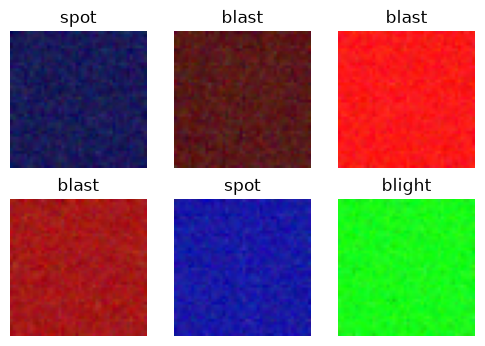

In [41]:
toy_dls = ImageDataLoaders.from_folder(toy_trn, valid_pct=0.2, seed=42, item_tfms=Resize(48), bs=16)   # label = folder name
toy_dls.show_batch(max_n=6, figsize=(6, 4))

In [42]:
# Train with the REAL fastai callback. bs=16, and GradientAccumulation(32): update only after 32 images = every 2 batches.
learn = vision_learner(toy_dls, resnet18, pretrained=False, metrics=error_rate)   # pretrained=False: no download, random start
learn.fit_one_cycle(8, 3e-3, cbs=GradientAccumulation(32))

epoch,train_loss,valid_loss,error_rate,time
0,0.445155,1.388314,0.430556,00:09
1,0.242418,1.507593,0.416667,00:03
2,0.344733,0.633938,0.083333,00:03
3,0.431366,0.340074,0.152778,00:03
4,0.433131,0.699071,0.208333,00:03
5,0.432565,0.006178,0.000000,00:03
6,0.344968,0.002904,0.000000,00:03
7,0.262438,0.003202,0.000000,00:03


**What the lines do**
- `ImageDataLoaders.from_folder(...)`: builds the data pipeline for "one folder per class" datasets. `valid_pct=0.2` keeps 20% for validation, `seed=42` makes that split repeatable, `item_tfms=Resize(48)` resizes each image, `bs=16` is the batch size.
- `vision_learner(toy_dls, resnet18, pretrained=False, ...)`: a standard image model (ResNet-18). `pretrained=False` starts from random weights, so nothing is downloaded. (The real Paddy runs use `pretrained` weights, which is why they need internet on Kaggle.)
- `cbs=GradientAccumulation(32)`: attaches the callback. We cannot *see* the memory saving on a CPU, but the training runs normally, confirming that it plugs in with one argument.

The toy images are very easy (the colour alone gives the class), so `error_rate` should fall close to 0 within a few epochs. The point here is the mechanics (the callback plugs in with one argument and training still works), not the accuracy.

## The Kaggle-only part: memory-test, train and ensemble the real models
**Everything from here to the end of Part B needs the Paddy data, `timm` and a GPU.** On your PC each cell prints a "skipped" message. On Kaggle (see the setup steps at the top) they run for real.

### Setting up the data

In [44]:
if RUN_PADDY:
    path = PADDY_PATH
    set_seed(42)
    tst_files = get_image_files(path/'test_images').sorted()      # all test images, sorted so predictions line up with the sample file
    df = pd.read_csv(path/'train.csv')
    print(len(tst_files), 'test images')
    print(df.label.value_counts())                                # how many training images per condition
else:
    print('SKIPPED (needs Kaggle GPU + Paddy data + timm). See the notes at the top of this notebook.')

SKIPPED (needs Kaggle GPU + Paddy data + timm). See the notes at the top of this notebook.


**What the lines do**
- `get_image_files(...)`: fastai helper that lists every image file under a folder. `.sorted()` makes the order deterministic: very important, because the submission file must list predictions in the same order as the sample submission.
- `df.label.value_counts()`: counts images per condition. One of them, `bacterial_panicle_blight`, has the **fewest** images.

### A quick way to test memory: use the smallest class
Memory use depends on the **model, image size and batch size**, not on how many images there are. So to find out whether a model fits, we train on only the smallest folder: one very short epoch, but the same memory footprint. That saves hours.

In [45]:
if RUN_PADDY:
    trn_path = path/'train_images'/'bacterial_panicle_blight'      # the smallest class (use it only for memory tests)

### The `train` function
This function is the whole recipe in six lines. Read it slowly:

In [46]:
if RUN_PADDY:
    def train(arch, size, item=Resize(480, method='squish'), accum=1, finetune=True, epochs=12):
        dls = ImageDataLoaders.from_folder(trn_path, valid_pct=0.2, item_tfms=item,
            batch_tfms=aug_transforms(size=size, min_scale=0.75), bs=64//accum)
        cbs = GradientAccumulation(64) if accum else []
        learn = vision_learner(dls, arch, metrics=error_rate, cbs=cbs).to_fp16()
        if finetune:
            learn.fine_tune(epochs, 0.01)
            return learn.tta(dl=dls.test_dl(tst_files))
        else:
            learn.unfreeze()
            learn.fit_one_cycle(epochs, 0.01)

**Line by line**
- `def train(arch, size, item=..., accum=1, finetune=True, epochs=12)`: `arch` = which pretrained model (a `timm` name string), `size` = the image size each batch is cropped/resized to, `item` = how each image is first resized, `accum` = the gradient-accumulation factor, `finetune` = full `fine_tune` or the faster `fit_one_cycle`, `epochs` = passes over the data.
- `ImageDataLoaders.from_folder(trn_path, valid_pct=0.2, ...)`: images in folders named after their class. **No `seed=42`** here, so each call gets a *different* random 80/20 split. That is deliberate: models that see different data make different mistakes, which makes an ensemble stronger.
- `item_tfms=item`: runs on each image **before batching**, on the CPU. `Resize(480, method='squish')` squashes the whole picture to 480x480 (no cropping, aspect ratio changes). `Resize((640,480))` keeps the 4:3 proportions.
- `batch_tfms=aug_transforms(size=size, min_scale=0.75)`: runs on each **batch**, on the GPU. It randomly flips/rotates/zooms/changes lighting (*augmentation*) and finally resizes to `size`. `min_scale=0.75` means a random crop keeps at least 75% of the picture.
- `bs=64//accum`: the batch size actually held in memory. `//` is integer division: `accum=2` gives `bs=32`.
- `cbs = GradientAccumulation(64) if accum else []`: always update after 64 images. (`accum=1` is also "truthy", so the callback is added then too; it is harmless: one batch of 64 already reaches 64.)
- `vision_learner(dls, arch, metrics=error_rate)`: builds a pretrained image model with a new head for our 10 classes. `error_rate` is the fraction of wrong predictions.
- `.to_fp16()`: **mixed precision**: does most arithmetic in 16-bit numbers, roughly halving memory and speeding up training on modern GPUs. Numbers are kept in 32-bit where accuracy matters.
- `learn.fine_tune(epochs, 0.01)`: first trains only the new head for 1 epoch (with the pretrained body frozen), then unfreezes and trains the whole model for `epochs`. `0.01` is the base learning rate.
- `learn.tta(dl=dls.test_dl(tst_files))`: **test-time augmentation**. `dls.test_dl(...)` makes a data loader for the unlabelled test images; `tta` predicts on several augmented copies of each and averages them. It returns `(predictions, targets)`.
- The `else` branch (`fit_one_cycle` after `unfreeze()`) is the quick option for memory tests: no separate head-only warm-up.

### Measure the memory use
The original notebook uses `torch.cuda.list_gpu_processes()`. That requires an extra library (`pynvml`) on some systems, so here we use PyTorch's built-in peak-memory counter instead, which needs nothing extra:

In [47]:
if RUN_PADDY:
    def report_gpu():
        # Peak GPU memory PyTorch allocated since the last reset, in GB, then free everything for the next test
        print('peak GPU memory: %.2f GB' % (torch.cuda.max_memory_allocated() / 1024**3))
        gc.collect()                                  # let Python free unused objects
        torch.cuda.empty_cache()                      # hand cached GPU memory back
        torch.cuda.reset_peak_memory_stats()          # restart the peak counter for the next test
    torch.cuda.reset_peak_memory_stats()

### Memory with and without accumulation
The original notebook measured a small model (`convnext_small`) with `accum` = 1, 2, 4. Expect memory to **fall each time you double `accum`**, but **not halve** it, because the model's weights and optimizer state take a fixed amount of memory regardless of batch size.

> **Model names:** `timm` renamed many models since the original notebook (2022). The old name `convnext_small_in22k` is now `convnext_small.fb_in22k`. If a name raises an error, list what is available, e.g. `import timm; timm.list_models('convnext_small*', pretrained=True)`, and use one from that list.

In [48]:
if RUN_PADDY:
    for accum in (1, 2, 4):
        print('accum =', accum, ' -> batch actually in memory =', 64//accum)
        train('convnext_small.fb_in22k', 128, epochs=1, accum=accum, finetune=False)
        report_gpu()

The original author's reading of this experiment (on a larger Kaggle GPU in 2022): roughly 5 GB at `accum=1`, 4 GB at 2, less again at 4. Your numbers will differ by GPU and library version; the *trend* is what matters.

### Checking the big models fit
For each architecture / size pair the author planned to use, he tried `accum=1`, and **doubled it whenever memory was above 16 GB.** It turned out `accum=2` was enough for all of them. This is the **full-size** list (it is slow, so this check only runs when you set `QUICK = False`):

In [49]:
if RUN_PADDY and not QUICK:
    big_checks = [('convnext_large.fb_in22k', 224), ('convnext_large.fb_in22k', (320, 240)),
                  ('vit_large_patch16_224.augreg_in21k_ft_in1k', 224),      # the original notebook's closest call to the 16 GB limit
                  ('swinv2_large_window12_192.ms_in22k', 192),
                  ('swin_large_patch4_window7_224.ms_in22k_ft_in1k', 224)]
    for arch, size in big_checks:
        print('---', arch, size)
        train(arch, size, epochs=1, accum=2, finetune=False)
        report_gpu()

### Which models and image-prep to use
After experimenting on small models, the author chose a handful of architectures, and for each one or two ways of preparing the images. A Python `dict` maps *architecture name* to a *set of (resize method, final size)* pairs. `res = 640,480` is the (width, height) of the original Paddy photos.

In [50]:
if RUN_PADDY:
    res = 640, 480

    # The original full-size plan (4 architectures, 6 training runs, 12 epochs each: hours of GPU time)
    models_full = {
        'convnext_large.fb_in22k': {(Resize(res), (320, 224))},
        'vit_large_patch16_224.augreg_in21k_ft_in1k': {(Resize(480, method='squish'), 224), (Resize(res), 224)},
        'swinv2_large_window12_192.ms_in22k': {(Resize(480, method='squish'), 192), (Resize(res), 192)},
        'swin_large_patch4_window7_224.ms_in22k_ft_in1k': {(Resize(res), 224)},
    }

    # A small version that finishes in minutes: two small models, small images
    models_quick = {
        'convnext_small.fb_in22k': {(Resize(480, method='squish'), 128)},
        'convnext_tiny.fb_in22k':  {(Resize(480, method='squish'), 128)},
    }

    models = models_quick if QUICK else models_full
    epochs = 2 if QUICK else 12
    print('training', sum(len(v) for v in models.values()), 'models for', epochs, 'epochs each')

**What the lines do**
- `Resize(res)`: resize to 640x480, **no squishing** (keeps the photo's shape). `Resize(480, method='squish')` squashes to a 480x480 square.
- Different architecture, size and resize give **diverse** models, which is what an ensemble needs.
- `set` (`{...}`) holds the combinations; `models.items()` below loops over `(architecture, combinations)`.
- `models = models_quick if QUICK else models_full`: a one-line switch.
- The author's note: the full version **timed out on Kaggle**, so he had to remove four runs from the submitted ensemble. That is why the quick version is the default here.

### Training all the models
We switch back to the full training set, then train each model in turn and **collect the test-set predictions** (after TTA) in a list called `tta_res`.

In [51]:
if RUN_PADDY:
    trn_path = path/'train_images'              # now the FULL training set (all 10 classes)
    tta_res = []                                # one entry per trained model: its (predictions, targets) on the test set

    for arch, details in models.items():
        for item, size in details:
            print('---', arch)
            print(size)
            print(item.name)
            tta_res.append(train(arch, size, item=item, accum=2, epochs=epochs))
            gc.collect()                        # free memory between models
            torch.cuda.empty_cache()

Each model gets a **different random validation split** (no seed), so the printed error rates are not directly comparable. Only the *test-set* predictions are kept: `train` returns `learn.tta(...)`, so each item of `tta_res` is a pair `(predictions, targets)`; for a test set the targets are not meaningful.

## Ensembling
An **ensemble** is a model made of other models. The simplest way is to **average their predictions**. Each model makes somewhat different errors, so the average cancels many of them out. Here is the idea on made-up numbers (this cell runs anywhere):

In [43]:
# Three pretend models predicting probabilities for 4 test images over 3 classes (each row sums to 1)
p1 = torch.tensor([[0.7, 0.2, 0.1], [0.4, 0.5, 0.1], [0.2, 0.2, 0.6], [0.5, 0.3, 0.2]])
p2 = torch.tensor([[0.6, 0.3, 0.1], [0.2, 0.7, 0.1], [0.3, 0.3, 0.4], [0.2, 0.6, 0.2]])
p3 = torch.tensor([[0.8, 0.1, 0.1], [0.5, 0.4, 0.1], [0.1, 0.3, 0.6], [0.3, 0.4, 0.3]])

for name, p in [('model 1', p1), ('model 2', p2), ('model 3', p3)]:
    print(name, 'picks classes', p.argmax(dim=1).tolist())

avg = torch.stack([p1, p2, p3]).mean(0)            # stack -> shape (3 models, 4 images, 3 classes); mean(0) averages over the models
print('ensemble picks    ', avg.argmax(dim=1).tolist())
print('ensemble probabilities:\n', avg)

model 1 picks classes [0, 1, 2, 0]
model 2 picks classes [0, 1, 2, 1]
model 3 picks classes [0, 0, 2, 1]
ensemble picks     [0, 1, 2, 1]
ensemble probabilities:
 tensor([[0.7000, 0.2000, 0.1000],
        [0.3667, 0.5333, 0.1000],
        [0.2000, 0.2667, 0.5333],
        [0.3333, 0.4333, 0.2333]])


**What the lines do**
- `torch.stack([...])`: stacks the three `(4, 3)` tables into one `(3, 4, 3)` block: model x image x class.
- `.mean(0)`: averages over dimension 0 (the models), leaving `(4, 3)`.
- `.argmax(dim=1)`: for each image, the class with the highest average probability: the ensemble's answer.
- Look at image 4 (the last row): model 1 picks class 0, but models 2 and 3 pick class 1, so the ensemble picks class 1 (average probability 0.43 versus 0.33). Image 2 is similar: model 3 disagrees with the other two, and the average sides with the majority. Because we average **probabilities** (not just votes), a confident model counts for more than an unsure one.

**Giving some models more weight.** In his experiments the author found `vit` models were a bit better than the rest, so he wanted them to count twice. The cheap way: add them to the list a second time.

In [44]:
preds_list = [p1, p2, p3]
preds_list += preds_list[1:3]                      # models 2 and 3 are now in the list twice -> they have double weight
print(len(preds_list), 'entries ->', 'weights: model1 x1, model2 x2, model3 x2')
torch.stack(preds_list).mean(0).argmax(dim=1).tolist()

5 entries -> weights: model1 x1, model2 x2, model3 x2


[0, 1, 2, 1]

`preds_list[1:3]` is a slice: elements at index 1 and 2 (the second and third). `+=` on a list *appends* those. (A weighted average would give the same result, but this is one line.)

### The real ensemble and submission file (Kaggle only)

In [54]:
if RUN_PADDY:
    save_pickle('tta_res.pkl', tta_res)                 # save the predictions in case the session crashes (training took ages)
    tta_prs = first(zip(*tta_res))                      # tta_res holds (preds, targets) pairs; zip(*...) separates them; first() = the preds
    if not QUICK and len(tta_prs) >= 3:
        tta_prs += tta_prs[1:3]                         # give the two vit models double weight, as in the original
    avg_pr = torch.stack(tta_prs).mean(0)               # average over models -> (n_test_images, 10)
    print(avg_pr.shape)

In [55]:
if RUN_PADDY:
    dls = ImageDataLoaders.from_folder(trn_path, valid_pct=0.2, item_tfms=Resize(480, method='squish'),
        batch_tfms=aug_transforms(size=224, min_scale=0.75))     # only needed to get dls.vocab: the class names in the right order
    idxs = avg_pr.argmax(dim=1)                                  # winning class number for each test image
    vocab = np.array(dls.vocab)                                  # class number -> class name
    ss = pd.read_csv(path/'sample_submission.csv')               # Kaggle's template: image_id, label
    ss['label'] = vocab[idxs]                                    # fill in the predicted names
    ss.to_csv('subm.csv', index=False)                           # the file to submit
    print(ss.head())
else:
    print('SKIPPED (needs Kaggle GPU + Paddy data + timm).')

SKIPPED (needs Kaggle GPU + Paddy data + timm).


**What the lines do**
- `first(zip(*tta_res))`: `zip(*pairs)` regroups a list of `(pred, target)` pairs into `(all preds, all targets)`; `first(...)` takes the first group, the predictions.
- `vocab[idxs]`: numpy lets you index with a whole array of numbers, converting 3,469 class numbers to class names in one go.
- `ss.to_csv('subm.csv', index=False)`: writes the CSV in Kaggle's required format. To submit from Kaggle's notebook: Output tab -> Submit to competition. From a PC: `kaggle competitions submit -c paddy-disease-classification -f subm.csv -m "message"`.

### What the author achieved
Four successive submissions, each ranked #1 on the leaderboard at the time: `convnext_small` (12 epochs, with TTA), `convnext_large` (same), the ensemble, and finally the ensemble with `vit` models double-weighted. The key take-away from the series: *very little code (the `train` function is six lines, the ensembling seven) plus a rigorous process of trying and measuring gives top results.*

### Part B summary
| Idea | Why | One-liner |
|---|---|---|
| Test memory on the smallest class | Memory does not depend on dataset size, so it is a cheap test | `trn_path = path/'train_images'/<small class>` |
| Gradient accumulation | Same as a big batch, less memory | `bs=64//accum`, `cbs=GradientAccumulation(64)` |
| Mixed precision | Smaller, faster | `.to_fp16()` |
| TTA | Steadier predictions | `learn.tta(dl=...)` |
| Ensemble | Averaging cancels out individual mistakes | `torch.stack(preds).mean(0)` |

---
# PART C: Multi-target model (disease **and** variety)

## What are we building?
So far, the model predicted one thing from each picture: the disease. Here we build **one** model that predicts **two** things: the **disease** *and* the **rice variety** (the Paddy data also tells us the variety of each plant).

## Why would we do that?
It sounds like it should distract the model from the main job. But the author has often found the opposite: giving the model **more to predict can improve its internal understanding of the image**, because it must learn features useful for both. For example, symptoms of a disease might look slightly different in different varieties, so learning to recognise varieties could help. He says honestly that he does not know whether it helps on this dataset, and encourages you to experiment. And if you actually *need* both outputs, a single model is cheaper than two.

## Three ingredients
1. **Data**: each image now has *two* labels. We build this with fastai's flexible `DataBlock`.
2. **Output size**: the model needs 10 outputs for disease plus 10 for variety = **20 numbers**.
3. **Loss and metrics**: we decide which of the 20 numbers belong to which target, and add the two losses.

We will do all three **twice**: first on our toy dataset (runs on your PC) and then on the real data (Kaggle).

### Step 1: look up the second label
The CSV lists each image's variety. We make `image_id` the index so we can look rows up by file name, and write a function that, given a file path, returns its variety. The toy dataset from Part B has the same structure, so we use it here (the real version is just below).

In [45]:
df_demo = toy_df                                                  # toy stand-in for: pd.read_csv(path/'train.csv', index_col='image_id')
print(df_demo.loc['blast_dark_0.png', 'variety'])                  # .loc[row_label, column] = look-up by index

def get_variety_toy(p): return df_demo.loc[p.name, 'variety']      # p is a file Path; p.name is just the file name
get_variety_toy(next((toy_trn/'blast').iterdir()))                 # try it on a real file path

dark


'bright'

**What the lines do**
- `df.loc['100330.jpg', 'variety']` (in the real data) returns the variety of that image. `.loc` looks up by **label** (the index), not by position.
- `get_variety(p)`: the `DataBlock` will hand us file paths (`Path` objects). `p.name` is the file name (e.g. `blast_dark_0.png`), which is our index. So this function turns a path into its second label.

### Step 2: the `DataBlock`
The `DataBlock` is fastai's "recipe" for turning raw files into a `DataLoaders`. You describe each piece of the recipe:

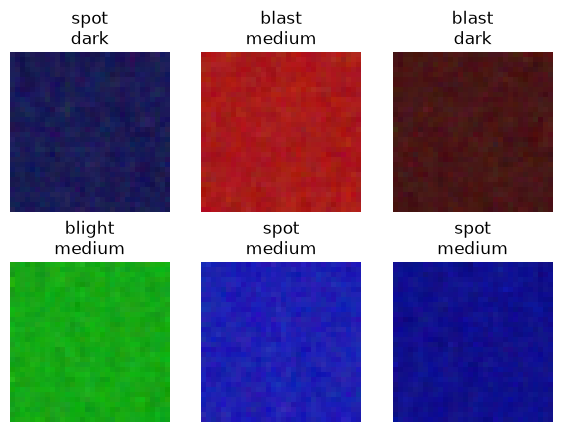

In [47]:
N_DIS, N_VAR = 3, 3         # how many diseases and varieties the TOY data has (the real data has 10 and 10)

toy_mt = DataBlock(
    blocks=(ImageBlock, CategoryBlock, CategoryBlock),        # three things per file: an image, a category, a category
    n_inp=1,                                                  # the first block is the INPUT; the other two are the targets
    get_items=get_image_files,                                # how to list the files
    get_y=[parent_label, get_variety_toy],                    # how to get each target: folder name, then variety lookup
    splitter=RandomSplitter(0.2, seed=42),                    # 80% train / 20% validation, repeatable
    item_tfms=Resize(48, method='squish'),                    # (toy sizes) per-image resize
    batch_tfms=aug_transforms(size=32, min_scale=0.75)        # per-batch augmentation + final size
)
toy_mt_dls = toy_mt.dataloaders(toy_trn, bs=16)
toy_mt_dls.show_batch(max_n=6, figsize=(7, 5))

**Line by line**
- `blocks=(ImageBlock, CategoryBlock, CategoryBlock)`: for each file we create **three** things: the picture, and two class labels. A `CategoryBlock` turns text labels into class numbers (and remembers which number is which name).
- `n_inp=1`: how many of the blocks are **inputs**. The first one (the image). The remaining two are the **targets** (what the model must predict). With a normal dataset we do not need this because the default is one input and one target.
- `get_items=get_image_files`: "to find the items, list all image files under the folder".
- `get_y=[parent_label, get_variety]`: one function per target, in order. `parent_label` (fastai) returns the **name of the folder** that contains the file: the disease. `get_variety` is our function from step 1.
- `splitter=RandomSplitter(0.2, seed=42)`: randomly hold out 20% for validation. The seed makes it repeatable.
- `item_tfms` and `batch_tfms`: same as in Part B: per-image resize first, then per-batch augmentation and resize. (The real data uses `Resize(192, method='squish')` and `size=128`.)
- `.dataloaders(path)`: runs the recipe on the folder and returns the training/validation `DataLoaders`.
- `show_batch` prints the images with **both** labels in the title: disease and variety.

### Step 3: first, a normal disease-only model on the new data
When the `DataLoaders` yields **three** things per item (image, disease, variety) instead of two, fastai's default loss and metric functions would receive three arguments and crash. So we wrap them to **ignore the variety**:

In [46]:
def disease_err(inp, disease, variety):  return error_rate(inp, disease)          # metric: only look at the disease target
def disease_loss(inp, disease, variety): return F.cross_entropy(inp, disease)      # loss:   only look at the disease target

- `inp` is the model's output for the batch. `disease` and `variety` are the two targets. The function **must accept all three**, even though it uses only two.
- `error_rate` = fraction wrong. `F.cross_entropy(inp, target)` is the standard loss for classification: it takes the model's raw scores (logits) and the correct class numbers, and is smaller when the model is both right and confident.

Now the learner. A new wrinkle: since there are two targets, fastai cannot guess how many outputs the model needs, so we **tell it** with `n_out` (the number of diseases in this single-target version):

In [59]:
learn = vision_learner(toy_mt_dls, resnet18, pretrained=False, loss_func=disease_loss,
                       metrics=disease_err, n_out=N_DIS)
learn.fit_one_cycle(8, 3e-3)

epoch,train_loss,valid_loss,disease_err,time
0,0.408165,0.497751,0.236111,00:03
1,0.420733,0.006947,0.000000,00:03
2,0.471877,0.002469,0.000000,00:03
3,0.350845,0.000748,0.000000,00:03
4,0.250913,0.000193,0.000000,00:03
5,0.233755,0.048535,0.000000,00:03
6,0.210037,0.001732,0.000000,00:03
7,0.169834,0.002226,0.000000,00:03


(On Kaggle with real data this is `vision_learner(dls, arch, loss_func=disease_loss, metrics=disease_err, n_out=10).to_fp16()` with `arch = 'convnext_small.fb_in22k'`, trained with `learn.fine_tune(5, 0.01)`.)

### Step 4: the multi-target model
Now we want predictions for **both** targets, so the model outputs `N_DIS + N_VAR` numbers (**20 in the real data**: 10 + 10). We decide that:
- the **first** `N_DIS` outputs are the scores for the diseases, and
- the **last** `N_VAR` outputs are the scores for the varieties.

Nothing in the model forces this; it is purely **how we write the loss**. The model learns to put disease information in the first group because that is where the loss looks.

First, a tiny demo with fake numbers so you can see the slicing (this is the heart of the whole notebook):

In [48]:
# A fake model output for 4 images: 3 disease scores then 3 variety scores per row (6 numbers per row)
fake_out = torch.tensor([[ 2.0, 0.1, 0.1,   0.2, 3.0, 0.1],
                         [ 0.1, 2.5, 0.2,   1.5, 0.2, 0.1],
                         [ 0.3, 0.2, 3.0,   0.1, 0.1, 2.0],
                         [ 1.8, 0.2, 0.1,   0.1, 0.2, 2.2]])
fake_disease = torch.tensor([0, 1, 2, 0])           # true disease numbers
fake_variety = torch.tensor([1, 0, 2, 2])           # true variety numbers

print('disease scores (first 3 columns):\n', fake_out[:, :3])
print('variety scores (last 3 columns): \n', fake_out[:, 3:])

d_loss = F.cross_entropy(fake_out[:, :3], fake_disease)    # loss using only the disease columns
v_loss = F.cross_entropy(fake_out[:, 3:], fake_variety)    # loss using only the variety columns
print('disease loss %.3f + variety loss %.3f = total %.3f' % (d_loss, v_loss, d_loss + v_loss))

disease scores (first 3 columns):
 tensor([[2.0000, 0.1000, 0.1000],
        [0.1000, 2.5000, 0.2000],
        [0.3000, 0.2000, 3.0000],
        [1.8000, 0.2000, 0.1000]])
variety scores (last 3 columns): 
 tensor([[0.2000, 3.0000, 0.1000],
        [1.5000, 0.2000, 0.1000],
        [0.1000, 0.1000, 2.0000],
        [0.1000, 0.2000, 2.2000]])
disease loss 0.221 + variety loss 0.255 = total 0.475


**What the lines do**
- `fake_out[:, :3]`: "all rows, columns 0 to 2" = the disease scores. `fake_out[:, 3:]`: "all rows, columns 3 onwards" = the variety scores. (In the real model it is `inp[:, :10]` and `inp[:, 10:]`.)
- Each slice goes into its own `cross_entropy` with its own target.
- The **total loss is the sum** of the two. Gradient descent now reduces both at once, so the shared "body" of the network must learn features helping both tasks.

Now as real functions (the toy uses `N_DIS = 3`; the real data `10`):

In [49]:
def disease_loss(inp, disease, variety):  return F.cross_entropy(inp[:, :N_DIS], disease)      # first N_DIS outputs -> disease
def variety_loss(inp, disease, variety):  return F.cross_entropy(inp[:, N_DIS:], variety)      # remaining outputs   -> variety
def combine_loss(inp, disease, variety):  return disease_loss(inp, disease, variety) + variety_loss(inp, disease, variety)

def disease_err(inp, disease, variety):   return error_rate(inp[:, :N_DIS], disease)           # error rate per target
def variety_err(inp, disease, variety):   return error_rate(inp[:, N_DIS:], variety)

err_metrics = (disease_err, variety_err)
all_metrics = err_metrics + (disease_loss, variety_loss)       # also show each loss separately as a "metric" while training

**What the lines do**
- Each function takes `(inp, disease, variety)`, the model output and the two targets, as fastai passes them.
- `combine_loss` is what is actually trained on. The others are only for **monitoring**: you can watch the disease error, the variety error, and each loss separately in the training table.
- `all_metrics = err_metrics + (disease_loss, variety_loss)`: tuples can be added; this builds one tuple of four things to display.

In [62]:
learn = vision_learner(toy_mt_dls, resnet18, pretrained=False, loss_func=combine_loss,
                       metrics=all_metrics, n_out=N_DIS + N_VAR)        # 6 outputs here (20 for the real data)
learn.fit_one_cycle(8, 3e-3)

epoch,train_loss,valid_loss,disease_err,variety_err,disease_loss,variety_loss,time
0,1.479006,3.934129,0.305556,0.694444,0.497348,3.436780,00:04
1,1.449800,2.962918,0.236111,0.486111,1.082325,1.880593,00:04
2,1.330400,1.356191,0.000000,0.208333,0.000889,1.355302,00:04
3,1.163406,0.036756,0.000000,0.000000,0.000380,0.036375,00:04
4,0.943914,0.023206,0.000000,0.000000,0.000460,0.022746,00:03
5,0.816028,0.023337,0.000000,0.000000,0.002489,0.020847,00:04
6,0.723652,0.015014,0.000000,0.000000,0.001569,0.013445,00:04
7,0.643510,0.015145,0.000000,0.000000,0.000877,0.014268,00:04


Look at the training table: it now shows `disease_err`, `variety_err`, `disease_loss` and `variety_loss`. On our toy data **both tasks are learnable** (colour tells the disease, brightness the variety), so both errors should drop.

> The toy images are far easier than real rice photos, so do not read anything into the accuracy numbers, and do not use the toy to decide whether multi-target "helps". The purpose is to see that the **plumbing works**: the `DataBlock` with three blocks, `n_inp=1`, a two-function `get_y`, `n_out` = sum of both, a summed loss, and sliced metrics.

### Check the predictions have both parts

In [50]:
x, d, v = toy_mt_dls.one_batch()                    # one batch: images, disease labels, variety labels
out = learn.model(x)                                # run the model ourselves to see its raw output (CPU)
print('model output shape:', tuple(out.shape), '-> 6 numbers per image (3 disease + 3 variety)')
print('disease true :', d[:6].tolist(), ' predicted:', out[:6, :N_DIS].argmax(dim=1).tolist())
print('variety true :', v[:6].tolist(), ' predicted:', out[:6, N_DIS:].argmax(dim=1).tolist())

model output shape: (16, 3) -> 6 numbers per image (3 disease + 3 variety)
disease true : [2, 0, 2, 0, 1, 0]  predicted: [2, 0, 2, 0, 1, 0]


IndexError: argmax(): Expected reduction dim 1 to have non-zero size.

`out[:, :N_DIS].argmax(dim=1)` and `out[:, N_DIS:].argmax(dim=1)` apply the *same slicing as the loss* to read off each prediction. If you want both answers at inference time, you must slice the same way.

## The Kaggle-only part: the real multi-target model
Same code with the real sizes. Needs the Paddy data, `timm` and a GPU. On your PC these cells are skipped.

In [64]:
if RUN_PADDY:
    N_DIS, N_VAR = 10, 10                                        # the real data: 10 conditions, 10 rice varieties
    trn_path = path/'train_images'
    df = pd.read_csv(path/'train.csv', index_col='image_id')      # image_id as the index (see Step 1)
    def get_variety(p): return df.loc[p.name, 'variety']

    dls = DataBlock(
        blocks=(ImageBlock, CategoryBlock, CategoryBlock),
        n_inp=1,
        get_items=get_image_files,
        get_y=[parent_label, get_variety],
        splitter=RandomSplitter(0.2, seed=42),
        item_tfms=Resize(192, method='squish'),
        batch_tfms=aug_transforms(size=128, min_scale=0.75)
    ).dataloaders(trn_path)
    dls.show_batch(max_n=6)
else:
    print('SKIPPED (needs Kaggle GPU + Paddy data + timm).')

SKIPPED (needs Kaggle GPU + Paddy data + timm).


In [65]:
if RUN_PADDY:
    arch = 'convnext_small.fb_in22k'      # (originally 'convnext_small_in22k')
    lr = 0.01
    EPOCHS_C = 3 if QUICK else 5

    # (1) the usual disease-only model, for comparison
    def disease_err(inp, disease, variety):  return error_rate(inp, disease)
    def disease_loss(inp, disease, variety): return F.cross_entropy(inp, disease)
    learn = vision_learner(dls, arch, loss_func=disease_loss, metrics=disease_err, n_out=10).to_fp16()
    learn.fine_tune(EPOCHS_C, lr)

In [66]:
if RUN_PADDY:
    # (2) the multi-target model: 20 outputs (10 disease + 10 variety), summed loss
    def disease_loss(inp, disease, variety): return F.cross_entropy(inp[:, :N_DIS], disease)
    def variety_loss(inp, disease, variety): return F.cross_entropy(inp[:, N_DIS:], variety)
    def combine_loss(inp, disease, variety): return disease_loss(inp, disease, variety) + variety_loss(inp, disease, variety)
    def disease_err(inp, disease, variety):  return error_rate(inp[:, :N_DIS], disease)
    def variety_err(inp, disease, variety):  return error_rate(inp[:, N_DIS:], variety)
    all_metrics = (disease_err, variety_err, disease_loss, variety_loss)

    learn = vision_learner(dls, arch, loss_func=combine_loss, metrics=all_metrics, n_out=20).to_fp16()
    learn.fine_tune(EPOCHS_C, lr)

**What to look at:** compare the final `disease_err` of run (1) with run (2). Is the multi-target model better, the same, or worse? With only a few epochs the difference will be small and partly random (a different seed can flip the result), so as the author says, to learn anything you need more epochs and repeated runs. He suspects it helps most **when overfitting is a problem**, i.e. when you train for many epochs.

### Part C summary
| Ingredient | Single target | Multi-target |
|---|---|---|
| `blocks` | `(ImageBlock, CategoryBlock)` | `(ImageBlock, CategoryBlock, CategoryBlock)` plus `n_inp=1` |
| `get_y` | one function | a list of functions |
| `n_out` | number of classes | sum of the classes of every target |
| loss | `cross_entropy` | sum of `cross_entropy` on each **slice** of the output |
| metrics | `error_rate` | one per slice (plus per-slice losses) |

---
# Lesson 7: the big picture
1. **Embeddings** are trained lookup tables. Dot product (+ bias, + weight decay) gives a strong recommender; concatenating embeddings into a neural network is the "deep" version, handy when you also have extra columns.
2. **Gradient accumulation** gives you large-batch training on a small GPU: smaller batches, losses scaled by `batch/target`, one update every `target` items.
3. **Ensembles** of models trained on different data splits, sizes and architectures are an easy win: `torch.stack(preds).mean(0)`.
4. **Multi-target** models need only a bigger output and a loss function that knows which slice belongs to which target.

**Next steps you can try:** on Kaggle, set `QUICK = False`; in Part A, change `n_factors` and `wd` and watch the validation loss; in Part C, train 10+ epochs and see whether multi-target starts to help.